# Descriptive analysis: intraday returns and factor dependence

Reproduces Table 1 and the intraday return profile and adapts the factor-dependence figure from Aleti, Bollerslev and Siggaard (2025). The analysis uses 1996–2020 log returns; forecasting elsewhere in the repository uses simple returns. Run the cells in order after installing the project and supplying the monthly input files. See the repository README for methods and results.

In [1]:
import datetime as dt
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

from hf_factor_zoo import data_processing as dp

In [2]:
PROJECT_ROOT = dp.find_project_root(Path.cwd())

RETURNS_DATA_DIR = PROJECT_ROOT / "data" / "simple_returns_1min"
monthly_files = sorted(RETURNS_DATA_DIR.glob("*.parquet"))

output_directory = PROJECT_ROOT / "results" / "descriptive"

output_directory.mkdir(
    parents=True,
    exist_ok=True,
)

In [3]:
def annualize_log_returns_by_time(
    log_returns: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Averaged annual log returns grouped by clock time and corresponding CI.
    """
    n_years = log_returns.index.year.nunique()
    clock_time = log_returns.index.time
    avg_annual_log_returns = log_returns.groupby(clock_time).sum() / n_years
    avg_annual_realized_variation = log_returns.pow(2).groupby(clock_time).sum() / n_years

    avg_annual_volatility = np.sqrt(avg_annual_realized_variation)

    ci_95 = 1.96 * avg_annual_volatility / np.sqrt(n_years)
    return avg_annual_log_returns, ci_95

In [4]:
def calculate_avg_stats_across_portfolios(
    asset_returns: pd.DataFrame,
    market_returns: pd.Series,
    n_years: int,
) -> pd.Series:
    """
    Calculate cross-sectional average statistics for one portfolio group.

    Parameters
    ----------
    asset_returns
        Intraday 15-minute log returns. Rows are timestamps and
        columns are portfolios belonging to one group.
    market_returns
        Intraday 15-minute market log returns with the same index.
    n_years
        Number of sample years used for annualization.
    """

    if not asset_returns.index.equals(market_returns.index):
        raise ValueError(
            "Asset and market returns must have identical timestamps in the same order."
        )
    if not asset_returns.index.is_unique:
        raise ValueError("Return timestamps must be unique.")

    if not asset_returns.index.is_monotonic_increasing:
        raise ValueError("Return timestamps must be sorted chronologically.")

    # Average annual log-returns
    avg_annual_log_returns = (asset_returns.sum() / n_years).mean()

    # Realized variation
    realized_variation = asset_returns.pow(2).sum()
    annual_realized_volatility = np.sqrt(realized_variation / n_years)
    # Average annualized realized volatility
    avg_annual_realized_volatility = annual_realized_volatility.mean()

    # Average bipower variation
    bipower_variation = (
        asset_returns.mul(asset_returns.shift(1)).fillna(0).abs().mul(np.pi / 2).sum()
    )
    avg_annual_bipower_variation = (bipower_variation / n_years).mean()

    # Average relative jump measure
    avg_relative_jump_measure = (
        (realized_variation - bipower_variation) / realized_variation
    ).mean()

    # Average autocorrelation
    avg_autocorrelation = (
        asset_returns.mul(asset_returns.shift(1)).sum().div(realized_variation).mean()
    )

    market_realized_variation = market_returns.pow(2).sum()
    correlation_with_market = (
        asset_returns.mul(market_returns, axis="index")
        .sum()
        .div(np.sqrt(realized_variation) * np.sqrt(market_realized_variation))
    )
    avg_correlation_with_market = correlation_with_market.mean()

    return pd.Series(
        {
            "Return": avg_annual_log_returns,
            "Realized volatility": avg_annual_realized_volatility,
            "Bipower Variation": avg_annual_bipower_variation,
            "Relative jump measure": avg_relative_jump_measure,
            "Autocorrelation": avg_autocorrelation,
            "Correlation with market": avg_correlation_with_market,
        }
    )

## Load and aggregate returns

Aggregate within each date into right-closed 15-minute bins. Keep observed intervals; do not fill missing bars with zero.

In [5]:
log_returns_15m_month_dfs = []
for data_file in monthly_files:
    if data_file.is_file():
        log_returns = dp.get_resampled_month_log_returns(data_file)
        log_returns_15m_month_dfs.append(log_returns)
log_returns_15m = pd.concat(log_returns_15m_month_dfs, axis=0).sort_index()
assert log_returns_15m.index.is_monotonic_increasing
assert log_returns_15m.index.is_unique

In [6]:
ff6_group = log_returns_15m.columns[log_returns_15m.columns.str.startswith("ff__")]
ind48_group = log_returns_15m.columns[log_returns_15m.columns.str.startswith("ind48__")]
cha218_group = log_returns_15m.columns[log_returns_15m.columns.str.startswith(("cz__", "jkp__"))]

## Intraday market-return profile

The 09:30 observation is the close-to-open return. The other slots describe regular-session returns.

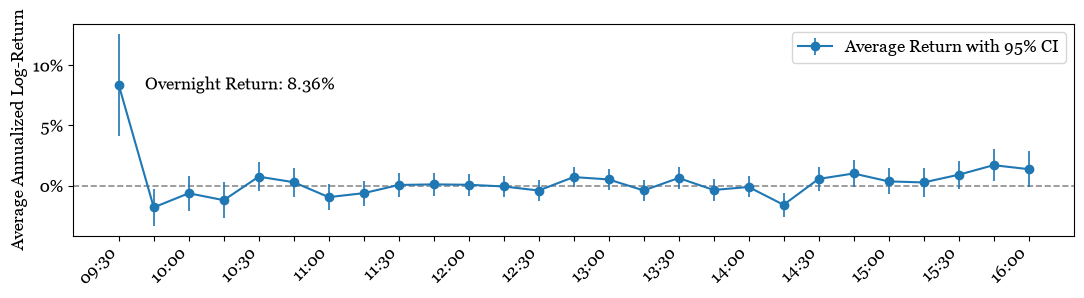

In [7]:
ff6_log_returns_15m = log_returns_15m[ff6_group]
ff6_avg_annual_log_returns, ci_95 = annualize_log_returns_by_time(ff6_log_returns_15m)

# Select and align the market-return series
mkt_avg_annual_log_returns = ff6_avg_annual_log_returns["ff__mkt"]
mkt_ci = ci_95.loc[mkt_avg_annual_log_returns.index, "ff__mkt"]

# One x-position for each of the 27 clock times
x = np.arange(len(mkt_avg_annual_log_returns))
time_labels = [time.strftime("%H:%M") for time in mkt_avg_annual_log_returns.index]

# Match the paper's typography and dimensions
mpl.rcParams["font.family"] = "Georgia"
mpl.rcParams["font.size"] = 12

fig, ax = plt.subplots(figsize=(11, 3))

# Point estimates, connecting line, and 95% confidence intervals
ax.errorbar(
    x,
    mkt_avg_annual_log_returns,
    yerr=mkt_ci,
    marker="o",
    markersize=6,
    linewidth=1.5,
    elinewidth=1.2,
    capsize=0,
    label="Average Return with 95% CI",
)

# Dashed horizontal line at zero
ax.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1.2,
    alpha=0.9,
    zorder=0,
)

# Label the overnight return
overnight_return = mkt_avg_annual_log_returns.iloc[0]

ax.text(
    0.75,
    overnight_return,
    f"Overnight Return: {overnight_return:.2%}",
    ha="left",
    va="center",
)

# Add all tick positions
ax.set_xticks(x)
ax.set_xticklabels(
    time_labels,
    rotation=45,
    ha="right",
)

# Show every second label: 09:30, 10:00, 10:30, ...
for i, label in enumerate(ax.get_xticklabels()):
    if i % 2 != 0:
        label.set_visible(False)

# Format y-axis decimals as percentages
ax.yaxis.set_major_formatter(
    mpl.ticker.PercentFormatter(
        xmax=1,
        decimals=0,
    )
)

ax.set_ylabel("Average Annualized Log-Return")
ax.set_xlabel(None)
ax.legend(loc="upper right")

fig.tight_layout()

plt.show()

In [8]:
figure1_data = pd.DataFrame(
    {
        "annual_log_return": mkt_avg_annual_log_returns,
        "ci_95": mkt_ci,
        "ci_lower": mkt_avg_annual_log_returns - mkt_ci,
        "ci_upper": mkt_avg_annual_log_returns + mkt_ci,
    }
)

figure1_data.index = [time.strftime("%H:%M") for time in figure1_data.index]
figure1_data.index.name = "clock_time"

figure1_data.to_csv(output_directory / "figure1_data.csv")

fig.savefig(
    output_directory / "figure1_intraday_market_returns.pdf",
    bbox_inches="tight",
)

fig.savefig(
    output_directory / "figure1_intraday_market_returns.png",
    dpi=300,
    bbox_inches="tight",
)

## Portfolio statistics

The table excludes overnight returns. Characteristic portfolios use fixed economic-sign metadata.

In [9]:
intraday_log_returns_15m = log_returns_15m.loc[log_returns_15m.index.time != dt.time(9, 30)]
intraday_log_returns_15m.head()

,cz__abnormalaccruals,cz__adexp,cz__ageipo,cz__announcementreturn,cz__aop,cz__betatailrisk,cz__betavix,cz__bmdec,cz__bpebm,cz__brandinvest,...,jkp__taccruals_at,jkp__taccruals_ni,jkp__tangibility,jkp__tax_gr1a,jkp__turnover_126d,jkp__turnover_var_126d,jkp__z_score,jkp__zero_trades_126d,jkp__zero_trades_21d,jkp__zero_trades_252d
datetime,,,,,,,,,,,,,,,,,,,,,
1996-01-02 09:45:00,-0.000203,0.005280,0.001154,0.000166,0.001217,-0.000047,-0.001103,0.000057,0.000021,-0.000716,...,-0.000124,-0.000715,0.000067,-0.001628,-0.001677,0.000731,-0.000798,0.001949,0.001996,0.001842
1996-01-02 10:00:00,0.001290,0.001297,0.000980,0.000058,-0.000646,-0.000743,0.002082,-0.000748,-0.000714,-0.003629,...,0.000180,-0.000133,0.001077,0.001372,-0.000025,-0.001560,-0.000278,0.000105,-0.000094,0.000108
1996-01-02 10:15:00,0.000208,0.001418,-0.001079,0.001726,0.000692,-0.000362,-0.000914,-0.002809,-0.000970,-0.003098,...,-0.000489,-0.000445,0.000302,0.002080,-0.000467,-0.005774,0.000964,0.000107,0.000225,0.000087
1996-01-02 10:30:00,0.000229,0.000544,0.001802,-0.000787,-0.000310,0.000623,0.001258,0.000267,0.000273,0.000473,...,-0.000660,-0.000431,-0.000106,-0.000407,0.000733,0.000601,0.000115,-0.000688,-0.000969,-0.000859
1996-01-02 10:45:00,0.000333,-0.000153,0.000838,-0.000358,0.000412,-0.000271,0.000699,-0.000489,-0.000958,-0.000969,...,-0.000282,-0.000106,-0.000192,0.000601,-0.000639,-0.000705,-0.000092,0.000734,0.000711,0.000871


In [10]:
ff6_intraday_log_returns = intraday_log_returns_15m[ff6_group]
ff6_stats = calculate_avg_stats_across_portfolios(
    asset_returns=ff6_intraday_log_returns,
    market_returns=ff6_intraday_log_returns["ff__mkt"],
    n_years=25,
)
ff6_stats_percent = ff6_stats.mul(100).round(2)
ff6_stats_percent

Return                     3.74
Realized volatility        8.59
Bipower Variation          0.80
Relative jump measure      4.75
Autocorrelation            6.11
Correlation with market    0.68
dtype: float64

In [11]:
mkt_stats = calculate_avg_stats_across_portfolios(
    asset_returns=ff6_intraday_log_returns[["ff__mkt"]],
    market_returns=ff6_intraday_log_returns["ff__mkt"],
    n_years=25,
)
mkt_stats_percent = mkt_stats.mul(100).round(2)
mkt_stats_percent

Return                       1.07
Realized volatility         14.42
Bipower Variation            2.02
Relative jump measure        2.76
Autocorrelation              3.56
Correlation with market    100.00
dtype: float64

In [12]:
ind48_intraday_log_returns_15m = intraday_log_returns_15m[ind48_group]
ind48_stats = calculate_avg_stats_across_portfolios(
    asset_returns=ind48_intraday_log_returns_15m,
    market_returns=intraday_log_returns_15m["ff__mkt"],
    n_years=25,
)
ind48_stats_percent = ind48_stats.mul(100).round(2)
ind48_stats_percent

Return                      1.32
Realized volatility        19.62
Bipower Variation           3.85
Relative jump measure       5.21
Autocorrelation             3.28
Correlation with market    67.32
dtype: float64

In [13]:
cha218_sign_info_file = PROJECT_ROOT / "docs" / "factor_cite_info_fmt.xlsx"
cha218_sign = pd.read_excel(cha218_sign_info_file, usecols=["Name", "Sign"])
cha218_sign = cha218_sign[cha218_sign["Name"].isin(cha218_group)].set_index("Name")["Sign"]

In [14]:
cha218_intraday_log_returns_15m = intraday_log_returns_15m[cha218_group]
signed_cha218_intraday_log_returns_15m = cha218_intraday_log_returns_15m.mul(
    cha218_sign, axis="columns"
)

In [15]:
cha218_stats = calculate_avg_stats_across_portfolios(
    asset_returns=signed_cha218_intraday_log_returns_15m,
    market_returns=intraday_log_returns_15m["ff__mkt"],
    n_years=25,
)
cha218_stats_percent = cha218_stats.mul(100).round(2)
cha218_stats_percent

Return                     2.93
Realized volatility        8.87
Bipower Variation          0.83
Relative jump measure      4.69
Autocorrelation            4.00
Correlation with market   -9.28
dtype: float64

In [16]:
descriptive_stats_df = pd.concat(
    [
        mkt_stats_percent.rename("Market"),
        ff6_stats_percent.rename("FF6"),
        ind48_stats_percent.rename("Industry 48"),
        cha218_stats_percent.rename("Characteristic-Sorted 218"),
    ],
    axis=1,
)

table1_reproduced = descriptive_stats_df.drop(index="Bipower Variation")
table1_reproduced.to_csv(
    output_directory / "table1_reproduced.csv",
    index_label="Statistic",
)

descriptive_stats_df

,Market,FF6,Industry 48,Characteristic-Sorted 218
Return,1.07,3.74,1.32,2.93
Realized volatility,14.42,8.59,19.62,8.87
Bipower Variation,2.02,0.80,3.85,0.83
Relative jump measure,2.76,4.75,5.21,4.69
Autocorrelation,3.56,6.11,3.28,4.00
Correlation with market,100.00,0.68,67.32,-9.28


## Dependence among characteristic factors

Both heatmaps include overnight observations and use the same 218 sign-adjusted factors. Factors are ordered by economic cluster size/name and then factor name; lag-one rows refer to the preceding observed interval.

In [17]:
cha218_cluster_info_file = PROJECT_ROOT / "docs" / "cluster_classifications.csv"
cha218_cluster = pd.read_csv(cha218_cluster_info_file)
cha218_cluster

,factor,Classification
0,cz__abnormalaccruals,Value
1,cz__adexp,Value
2,cz__ageipo,Value
3,cz__announcementreturn,Momentum
4,cz__aop,Leverage
...,...,...
213,jkp__turnover_var_126d,Profitability
214,jkp__z_score,Leverage
215,jkp__zero_trades_126d,Low Risk
216,jkp__zero_trades_21d,Low Risk


In [18]:
signed_cha218_log_returns_15m = log_returns_15m[cha218_group].mul(cha218_sign, axis="columns")

# Map each factor to its economic cluster
cha218_cluster_map = cha218_cluster.set_index("factor")["Classification"]

# Build an ordering table
factor_order = pd.DataFrame({"factor": cha218_group})
factor_order["cluster"] = factor_order["factor"].map(cha218_cluster_map)

factor_order["cluster_size"] = factor_order.groupby("cluster")["factor"].transform("size")

# Largest clusters first; alphabetical tie-breaking
factor_order = factor_order.sort_values(
    ["cluster_size", "cluster", "factor"],
    ascending=[False, True, True],
).reset_index(drop=True)

# Sort columns by factor identifier before assigning cluster labels
signed_cha218_log_returns_15m = signed_cha218_log_returns_15m.loc[
    :, factor_order["factor"].tolist()
]

# Cluster labels support grouped heatmap ticks
signed_cha218_log_returns_15m.columns = pd.MultiIndex.from_frame(
    factor_order[["cluster", "factor"]]
)

signed_cha218_log_returns_15m = signed_cha218_log_returns_15m.rename_axis(index="datetime")

In [19]:
realized_variation = signed_cha218_log_returns_15m.pow(2).sum(axis=0)
realized_variation_product = pd.DataFrame(
    np.outer(realized_variation, realized_variation),
    index=realized_variation.index,
    columns=realized_variation.index,
)
realized_volatility_product = realized_variation_product.pipe(np.sqrt)
cross_correlation = (
    signed_cha218_log_returns_15m.T @ signed_cha218_log_returns_15m
) / realized_volatility_product

cross_autocorrelation_lag_1 = (
    signed_cha218_log_returns_15m.shift(1).fillna(0).T @ signed_cha218_log_returns_15m
) / realized_volatility_product

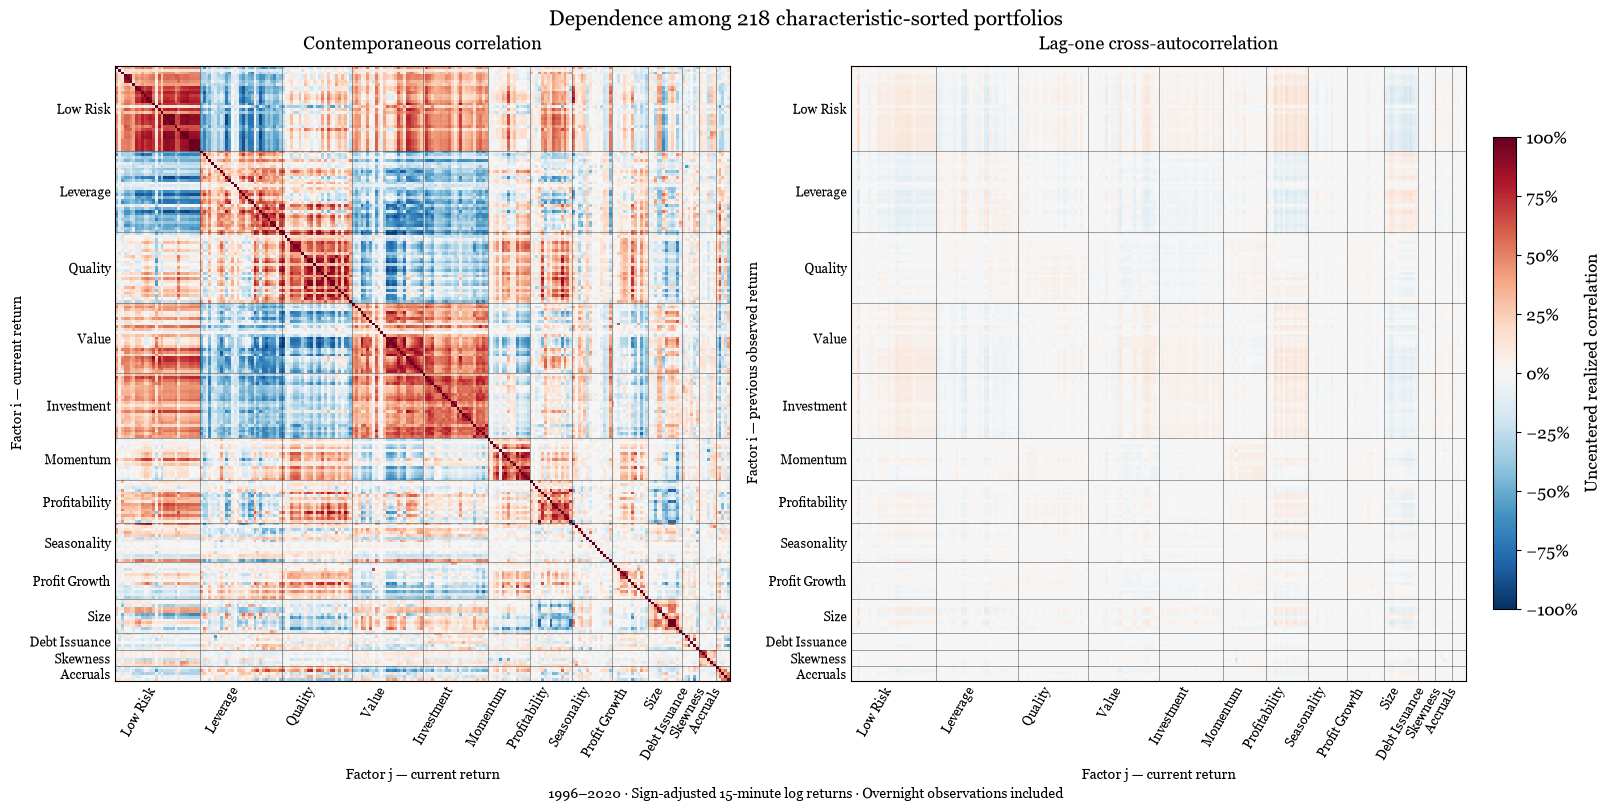

In [20]:
# Validate matrix labels and values
if not cross_correlation.index.equals(cross_correlation.columns):
    raise ValueError("Correlation rows and columns must have the same order.")

for matrix in (cross_correlation, cross_autocorrelation_lag_1):
    if not (
        matrix.index.equals(cross_correlation.index)
        and matrix.columns.equals(cross_correlation.columns)
    ):
        raise ValueError("Both matrices must use the same factor ordering.")

    if not np.isfinite(matrix.to_numpy()).all():
        raise ValueError("Correlation matrices contain missing or infinite values.")

# Find the start, end, and midpoint of each cluster block
clusters = cross_correlation.index.get_level_values("cluster").to_numpy()

block_starts = np.r_[
    0,
    np.flatnonzero(clusters[1:] != clusters[:-1]) + 1,
]
block_ends = np.r_[block_starts[1:], len(clusters)]

block_centers = (block_starts + block_ends - 1) / 2
cluster_labels = clusters[block_starts]

if len(set(cluster_labels)) != len(cluster_labels):
    raise ValueError("Some clusters appear in multiple separate blocks.")

# Create two heatmaps
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(16, 8),
    layout="constrained",
)

panels = [
    (
        cross_correlation,
        "Contemporaneous correlation",
        "Factor j — current return",
        "Factor i — current return",
    ),
    (
        cross_autocorrelation_lag_1,
        "Lag-one cross-autocorrelation",
        "Factor j — current return",
        "Factor i — previous observed return",
    ),
]

for ax, (matrix, title, xlabel, ylabel) in zip(axes, panels, strict=True):
    heatmap = ax.imshow(
        matrix.to_numpy(),
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        origin="upper",
        interpolation="nearest",
        aspect="equal",
    )

    # Show cluster names rather than all 218 factor names
    ax.set_xticks(
        block_centers,
        labels=cluster_labels,
        rotation=60,
        ha="right",
        fontsize=9,
    )
    ax.set_yticks(
        block_centers,
        labels=cluster_labels,
        fontsize=9,
    )

    # Separate adjacent clusters
    for boundary in block_starts[1:] - 0.5:
        ax.axhline(boundary, color="black", linewidth=0.5, alpha=0.5)
        ax.axvline(boundary, color="black", linewidth=0.5, alpha=0.5)

    ax.tick_params(axis="both", length=0)
    ax.set_title(title, fontsize=13, pad=12)
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.grid(False)

# Shared color scale
colorbar = fig.colorbar(
    heatmap,
    ax=axes,
    shrink=0.75,
    pad=0.02,
)

colorbar.set_label("Uncentered realized correlation")
colorbar.ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))

fig.suptitle(
    "Dependence among 218 characteristic-sorted portfolios",
    fontsize=15,
)

fig.supxlabel(
    "1996–2020 · Sign-adjusted 15-minute log returns · Overnight observations included",
    fontsize=10,
)

# Save before displaying
output_directory = PROJECT_ROOT / "results" / "descriptive"
output_directory.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_directory / "factor_dependence_heatmaps.pdf",
    bbox_inches="tight",
)

fig.savefig(
    output_directory / "factor_dependence_heatmaps.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()